# After context engineering: XGBoost and SAP RPT on the original data

## tl;dr
SAP RPT performs better **on fraud F1 and recall** with balanced in-context examples than with random examples at the same 128-row budget: F1 rises from **0.571 to 0.640**, and it finds **16 rather than 10 of 22** fraud cases. False alarms rise from **3 to 12**. In the balanced condition SAP RPT has higher fraud F1 than XGBoost (**0.640 versus 0.457**). Late-payment F1 does not improve. The saved first benchmark and both new conditions use the same original 128 test invoices.

## Context & methods
The source, labels and final test IDs are identical across these rows. The published first benchmark used 1,024 examples and carried both targets in its SAP request. The controlled context comparison uses 128 examples in each condition, selection seed 11, and one target per SAP request. XGBoost trains on each selected set with the original model seed, 20261002. SAP RPT receives it as labeled request context. See the [context workflow](../context_engineering/00_original_22_case_context_workflow.ipynb) for request masking and selection checks.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'archive/synthetic_invoice_experiments/published_baseline/payment_behavior.csv').exists())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
from context_engineering import assert_no_leakage, select_context
from run_context_benchmark import request_for, metric_row
source_path = ROOT / 'archive/synthetic_invoice_experiments/published_baseline/payment_behavior.csv'
source = pd.read_csv(source_path)
pool, holdout = source.iloc[:1024].copy(), source.iloc[1024:].copy()
targets = ('paid_late', 'is_fraud')
seed, budget = 11, 128
assert len(source) == 1152 and len(pool) == 1024 and len(holdout) == 128
assert int(holdout.is_fraud.sum()) == 22 and int(holdout.paid_late.sum()) == 51
assert source.invoice_id.is_unique and not source.isna().any().any()
assert_no_leakage(pool, holdout)


## Results
Recompute counts from saved predictions rather than trusting display text. A missing SAP condition stays missing until a live request succeeds.

In [2]:
saved = {'XGBoost': pd.read_csv(ROOT / 'data/synthetic_invoices/xgboost_results.csv'),
         'SAP-RPT': pd.read_csv(ROOT / 'data/synthetic_invoices/rpt16_results.csv')}
new = pd.read_csv(ROOT / 'data/original_context_comparison/results.csv')
predictions = pd.read_csv(ROOT / 'data/original_context_comparison/predictions.csv')
rows = []
for target in targets:
    for model, frame in saved.items():
        assert frame.invoice_id.tolist() == holdout.invoice_id.tolist()
        assert frame[f'actual_{target}'].tolist() == holdout[target].tolist()
        rows.append({'stage': 'first benchmark (1024 rows)', 'target': target, 'model': model,
                     **metric_row(holdout[target].to_numpy(), frame[f'predicted_{target}'].to_numpy())})
for result in new.itertuples():
    sample = predictions[predictions.run_id == result.run_id].set_index('invoice_id').loc[holdout.invoice_id]
    assert sample.actual.tolist() == holdout[result.target].tolist()
    checked = metric_row(sample.actual.to_numpy(), sample.predicted.to_numpy())
    assert checked['true_positives'] == result.true_positives
    assert checked['false_positives'] == result.false_positives
    rows.append({'stage': f'{result.strategy} (128 rows)', 'target': result.target,
                 'model': result.model, **checked})
comparison = pd.DataFrame(rows)
display(comparison[['stage', 'target', 'model', 'true_positives', 'false_positives',
                    'precision', 'recall', 'f1', 'accuracy']].round(3))


,stage,target,model,true_positives,false_positives,precision,recall,f1,accuracy
0,first benchmark (1024 rows),paid_late,XGBoost,32,25,0.561,0.627,0.593,0.656
1,first benchmark (1024 rows),paid_late,SAP-RPT,34,20,0.630,0.667,0.648,0.711
2,first benchmark (1024 rows),is_fraud,XGBoost,15,9,0.625,0.682,0.652,0.875
3,first benchmark (1024 rows),is_fraud,SAP-RPT,10,5,0.667,0.455,0.541,0.867
4,random (128 rows),paid_late,SAP-RPT,23,16,0.590,0.451,0.511,0.656
5,random (128 rows),is_fraud,SAP-RPT,10,3,0.769,0.455,0.571,0.883
6,balanced (128 rows),paid_late,SAP-RPT,26,26,0.500,0.510,0.505,0.602
7,balanced (128 rows),is_fraud,SAP-RPT,16,12,0.571,0.727,0.640,0.859
8,random (128 rows),paid_late,XGBoost,27,19,0.587,0.529,0.557,0.664
9,random (128 rows),is_fraud,XGBoost,10,20,0.333,0.455,0.385,0.750


### What improved for SAP RPT?
This is the controlled in-context learning comparison: only example selection changes between random and balanced contexts. The table reports percentage-point changes for recall, precision, and F1, plus invoice counts. Higher recall comes with more false alarms.

,Random 128,Balanced 128,Change
Measure,,,
Fraud cases found / 22,10.000,16.000,6.000
False alarms / 106,3.000,12.000,9.000
Fraud recall,0.455,0.727,0.273
Fraud precision,0.769,0.571,-0.198
Fraud F1,0.571,0.640,0.069


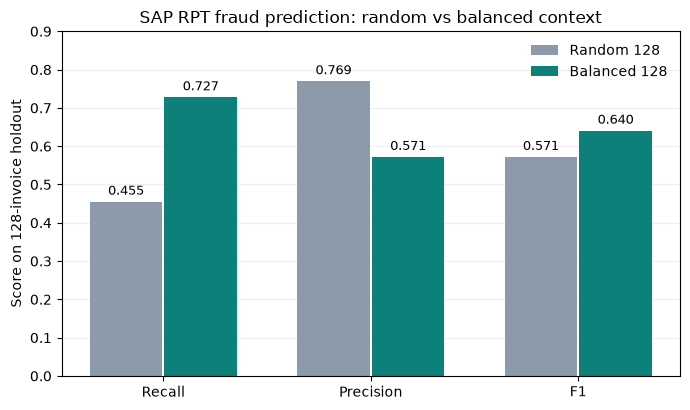

In [3]:
rpt_fraud = (comparison[(comparison.model == 'SAP-RPT') &
                         (comparison.target == 'is_fraud')]
             .set_index('stage'))
before = rpt_fraud.loc['random (128 rows)']
after = rpt_fraud.loc['balanced (128 rows)']
assert (int(before.true_positives), int(before.false_positives)) == (10, 3)
assert (int(after.true_positives), int(after.false_positives)) == (16, 12)
improvement = pd.DataFrame({
    'Measure': ['Fraud cases found / 22', 'False alarms / 106', 'Fraud recall',
                'Fraud precision', 'Fraud F1'],
    'Random 128': [before.true_positives, before.false_positives,
                   before.recall, before.precision, before.f1],
    'Balanced 128': [after.true_positives, after.false_positives,
                     after.recall, after.precision, after.f1],
})
improvement['Change'] = improvement['Balanced 128'] - improvement['Random 128']
display(improvement.set_index('Measure').round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
positions = np.arange(3)
metrics = ['recall', 'precision', 'f1']
for offset, condition, row, color in [(-.18, 'Random 128', before, '#8C9AA9'),
                                       (.18, 'Balanced 128', after, '#0E807A')]:
    values = [float(row[metric]) for metric in metrics]
    bars = ax.bar(positions + offset, values, width=.35, color=color, label=condition)
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=3, fontsize=9)
ax.set_xticks(positions, ['Recall', 'Precision', 'F1'])
ax.set_ylim(0, 0.9)
ax.set_ylabel('Score on 128-invoice holdout')
ax.set_title('SAP RPT fraud prediction: random vs balanced context')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


### Fraud detections and false alarms
Bars show counts on the same 22-positive holdout. Blank model conditions are not estimated from the eight-case pilot.

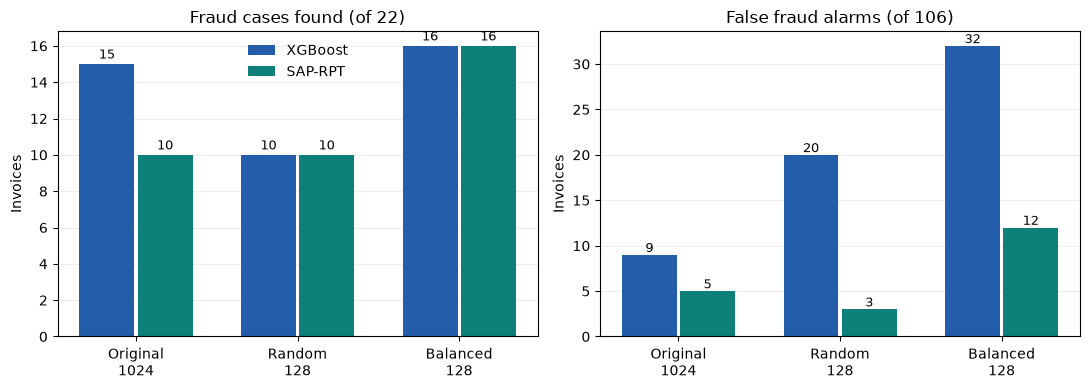

In [4]:
fraud = comparison[comparison.target == 'is_fraud']
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
stages = ['first benchmark (1024 rows)', 'random (128 rows)', 'balanced (128 rows)']
models = ['XGBoost', 'SAP-RPT']
colors = {'XGBoost': '#245EAA', 'SAP-RPT': '#0E807A'}
for ax, column, title in zip(axes, ['true_positives', 'false_positives'],
                             ['Fraud cases found (of 22)', 'False fraud alarms (of 106)']):
    for offset, model in [(-0.18, 'XGBoost'), (0.18, 'SAP-RPT')]:
        subset = fraud[fraud.model == model].set_index('stage')
        for index, stage in enumerate(stages):
            if stage in subset.index:
                value = int(subset.loc[stage, column])
                ax.bar(index + offset, value, width=0.34, color=colors[model],
                       label=model if index == 0 else None)
                ax.text(index + offset, value + 0.3, str(value), ha='center', fontsize=9)
    ax.set_xticks(range(3), ['Original\n1024', 'Random\n128', 'Balanced\n128'])
    ax.set_title(title)
    ax.set_ylabel('Invoices')
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()


## Takeaways
On the original 1,024-row benchmark, XGBoost found 15 of 22 fraud cases with nine false alarms; SAP RPT found 10 with five. At a matched 128-row budget, balancing raises fraud detections from 10 to 16 for both models. False alarms also rise, from 20 to 32 for XGBoost and from 3 to 12 for SAP RPT. Balanced-context fraud F1 is 0.457 for XGBoost and 0.640 for SAP RPT; SAP RPT wins that metric in this after condition. XGBoost has higher late-payment F1 (0.571 versus 0.505). Budget and SAP request schema changed from the first benchmark, so the 128-row random control is the proper comparison for selection alone. These rankings are descriptive for one synthetic split and one selection seed.